In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

### Load the Dataset

In [2]:
df = pd.read_csv('student_performance_data.csv')
df

,age,study_hours,assignment_completion_rate,attendance_percentage,motivation_level,stress_level,sleep_hours,final_grade
0,20,6.22,60.42,70.73,9,9,5.40,67.50
1,22,5.30,80.64,73.64,1,8,5.59,48.81
2,21,4.68,86.92,87.18,10,8,6.67,71.92
3,16,2.27,60.10,67.30,7,6,5.31,59.51
4,19,3.85,68.00,77.11,1,5,3.93,45.00
...,...,...,...,...,...,...,...,...
4995,19,3.11,55.81,57.00,1,3,3.68,38.57
4996,16,5.73,45.55,94.91,1,3,5.64,57.02
4997,21,1.57,67.25,89.26,2,2,6.41,68.17
4998,18,2.73,83.89,86.69,1,3,5.95,52.03


In [3]:
df.columns

Index(['age', 'study_hours', 'assignment_completion_rate',
       'attendance_percentage', 'motivation_level', 'stress_level',
       'sleep_hours', 'final_grade'],
      dtype='object')

In [4]:
df.head()

,age,study_hours,assignment_completion_rate,attendance_percentage,motivation_level,stress_level,sleep_hours,final_grade
0,20,6.22,60.42,70.73,9,9,5.40,67.50
1,22,5.30,80.64,73.64,1,8,5.59,48.81
2,21,4.68,86.92,87.18,10,8,6.67,71.92
3,16,2.27,60.10,67.30,7,6,5.31,59.51
4,19,3.85,68.00,77.11,1,5,3.93,45.00


In [5]:
df.shape

(5000, 8)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 8 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   age                         5000 non-null   int64  
 1   study_hours                 5000 non-null   float64
 2   assignment_completion_rate  5000 non-null   float64
 3   attendance_percentage       5000 non-null   float64
 4   motivation_level            5000 non-null   int64  
 5   stress_level                5000 non-null   int64  
 6   sleep_hours                 5000 non-null   float64
 7   final_grade                 5000 non-null   float64
dtypes: float64(5), int64(3)
memory usage: 312.6 KB


In [7]:
df.dtypes

age                             int64
study_hours                   float64
assignment_completion_rate    float64
attendance_percentage         float64
motivation_level                int64
stress_level                    int64
sleep_hours                   float64
final_grade                   float64
dtype: object

In [8]:
df.describe()

,age,study_hours,assignment_completion_rate,attendance_percentage,motivation_level,stress_level,sleep_hours,final_grade
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,18.954600,4.034010,69.711680,74.424804,5.579000,5.537600,6.510728,71.278562
std,2.540754,1.491618,17.742958,14.702201,2.836365,2.894868,1.200566,12.174121
min,15.000000,0.390000,39.060000,48.940000,1.000000,1.000000,3.000000,31.970000
25%,17.000000,2.960000,54.570000,61.777500,3.000000,3.000000,5.670000,62.890000
50%,19.000000,4.090000,69.365000,73.975000,6.000000,6.000000,6.500000,71.320000
75%,21.000000,5.050000,85.290000,87.092500,8.000000,8.000000,7.340000,79.542500
max,23.000000,8.580000,100.000000,100.000000,10.000000,10.000000,10.020000,100.000000


### Check null values

In [9]:
df.isnull().sum()

age                           0
study_hours                   0
assignment_completion_rate    0
attendance_percentage         0
motivation_level              0
stress_level                  0
sleep_hours                   0
final_grade                   0
dtype: int64

### Check duplicate values

In [10]:
df.duplicated().sum()

np.int64(0)

### Target Variable in Regression

In [11]:
df['final_grade'].value_counts()

final_grade
100.00    52
71.61      6
67.62      6
79.74      6
70.18      6
          ..
88.74      1
54.99      1
73.98      1
49.73      1
76.00      1
Name: count, Length: 2999, dtype: int64

## EDA

### Check Distributions

### Final grade distribution

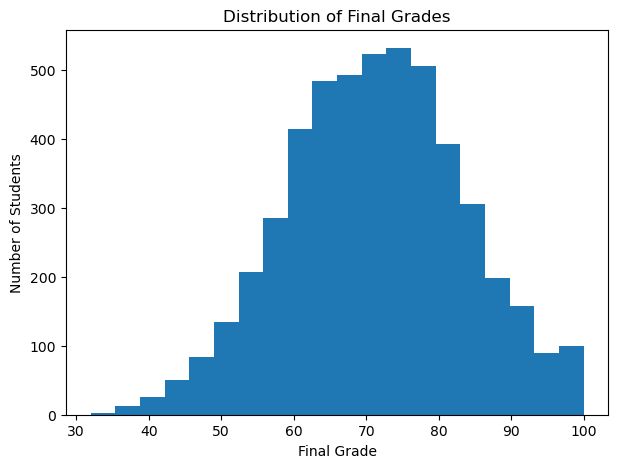

In [12]:
plt.figure(figsize=(7, 5))

plt.hist(df["final_grade"], bins=20)

plt.xlabel("Final Grade")
plt.ylabel("Number of Students")
plt.title("Distribution of Final Grades")

plt.show()

### Correlation

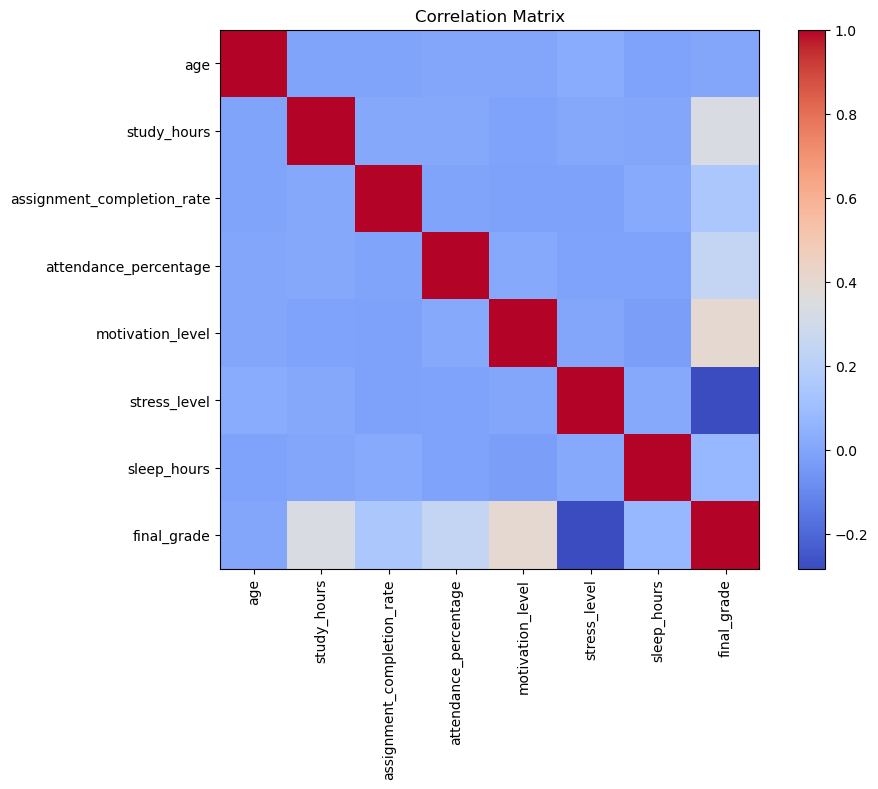

In [13]:
plt.figure(figsize = (10,7))

corr = df.corr()

plt.imshow(corr, cmap="coolwarm")

plt.colorbar()

plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)

plt.title("Correlation Matrix")

plt.show()

#### Feature vs Final Grade

### Study Hours vs Final Grade

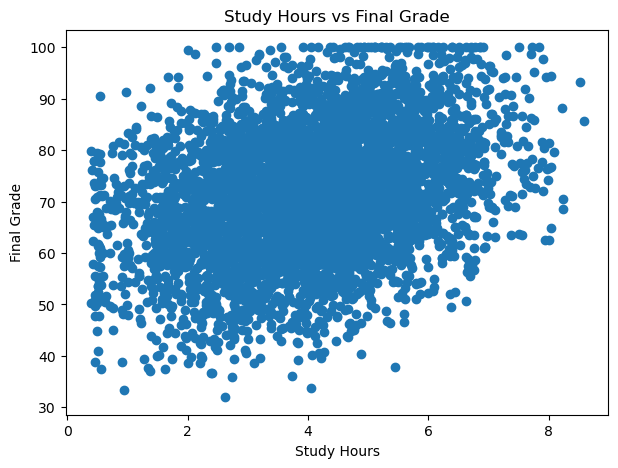

In [14]:
plt.figure(figsize=(7, 5))

plt.scatter(df["study_hours"], df["final_grade"])

plt.xlabel("Study Hours")
plt.ylabel("Final Grade")
plt.title("Study Hours vs Final Grade")

plt.show()

In [15]:
df.columns

Index(['age', 'study_hours', 'assignment_completion_rate',
       'attendance_percentage', 'motivation_level', 'stress_level',
       'sleep_hours', 'final_grade'],
      dtype='object')

### Attendance vs Final Grade

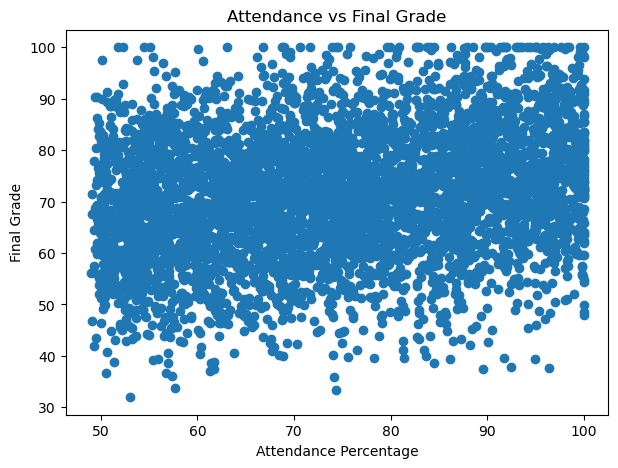

In [16]:
plt.figure(figsize=(7, 5))

plt.scatter(df["attendance_percentage"], df["final_grade"])

plt.xlabel("Attendance Percentage")
plt.ylabel("Final Grade")
plt.title("Attendance vs Final Grade")

plt.show()

### Assignment Completion vs Final Grade

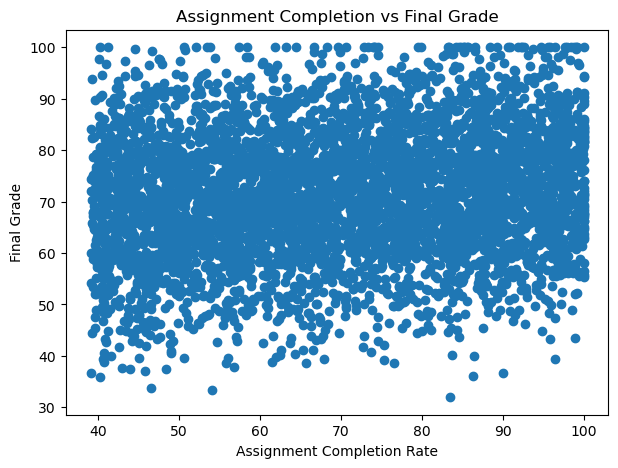

In [17]:
plt.figure(figsize=(7, 5))

plt.scatter(df['assignment_completion_rate'], df['final_grade'])

plt.xlabel("Assignment Completion Rate")
plt.ylabel("Final Grade")

plt.title("Assignment Completion vs Final Grade")

plt.show()

### Check Outliers

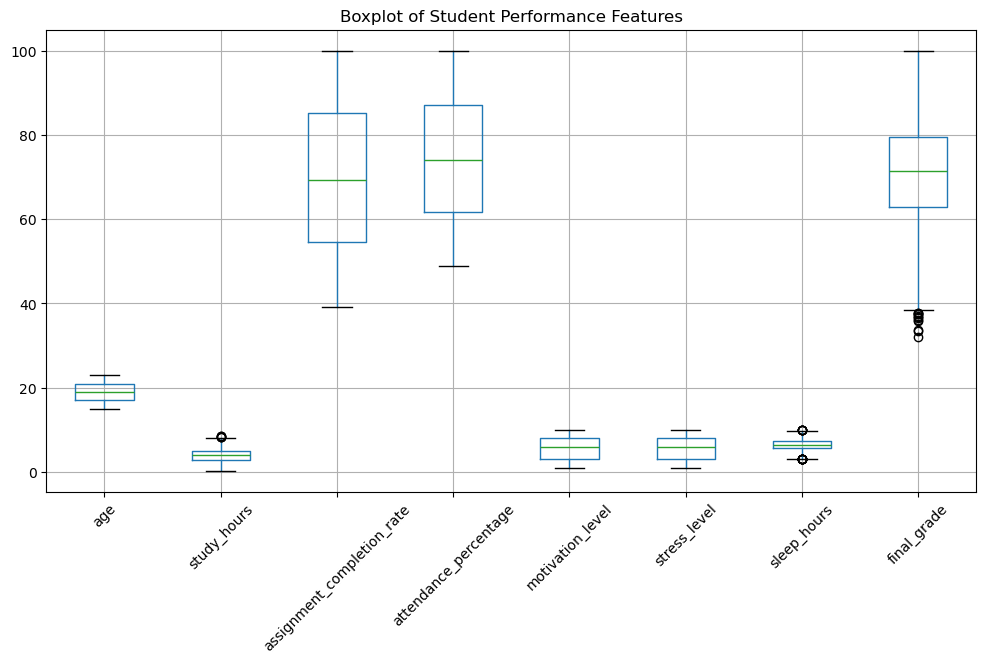

In [18]:
plt.figure(figsize=(12, 6))

df.boxplot()

plt.xticks(rotation=45)

plt.title("Boxplot of Student Performance Features")

plt.show()

In [ ]:
### but having realistic values

### For Checking Range

In [19]:
for column in df.columns:
    print(column,"Minimum =", df[column].min(),"Maximum =", df[column].max() )

age Minimum = 15 Maximum = 23
study_hours Minimum = 0.39 Maximum = 8.58
assignment_completion_rate Minimum = 39.06 Maximum = 100.0
attendance_percentage Minimum = 48.94 Maximum = 100.0
motivation_level Minimum = 1 Maximum = 10
stress_level Minimum = 1 Maximum = 10
sleep_hours Minimum = 3.0 Maximum = 10.02
final_grade Minimum = 31.97 Maximum = 100.0
